# Matplotlib (Plotting)
Autor: Leon Gjinovci  
Matplotlib ist eine low level graph plotting Bibliothek, geeignet zur Visualisierung, z.B. von DataFrames (pandas) in Python.

Basiert auf:
- https://github.com/matplotlib/matplotlib
- https://www.w3schools.com/python/matplotlib_intro.asp

## Installation
Modul über pip installieren:

> pip install matplotlib

Verwendung:
> import matplotlib.pyplot as plt

"plt" ist die konventionelle Abkürzung, so wie pandas mit "pd" abgekürzt wird.
Die wichtigsten Funktionalitäten für das Plotting sind im pyplot submodul vorhanden und wird üblicherweise importiert, statt dem gesamten Modul

## Erste Verwendung
Beispiel an Punkten in einem Raum:

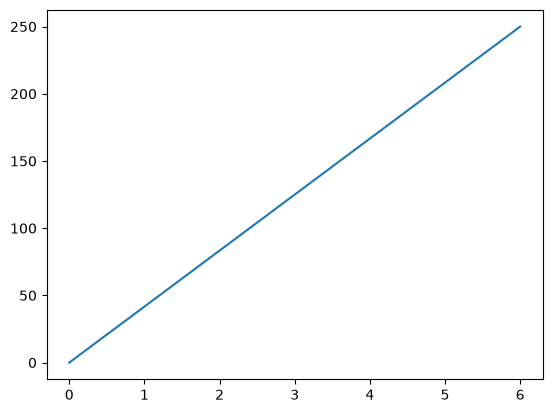

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

xpoints = np.array([0, 6]) # Erstellung eines Arrays für die x Achse
ypoints = np.array([0, 250]) # Erstellung eines Arrays für die y Achse

plt.plot(xpoints, ypoints) # Erstellen eines Lineplots (Standard) mit den Punktearrays als Args
plt.show() # Anzeige des Plots

Standardmäßig wird über .plot() ein Plot erstellt, der die einzelnen Punkte über Linien verbunden.

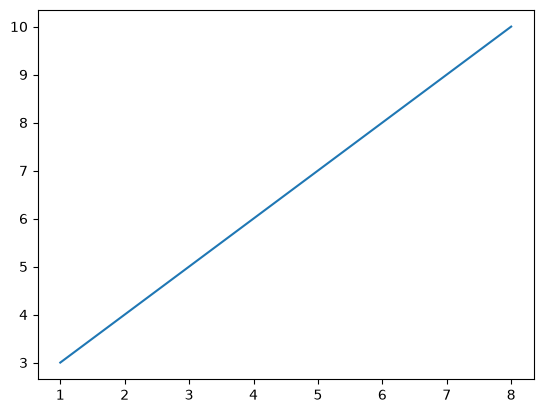

In [3]:
import matplotlib.pyplot as plt
import numpy as np

xpoints = np.array([1, 8])
ypoints = np.array([3, 10])

plt.plot(xpoints, ypoints)
plt.show()

## Beispiel an Pandas

In [30]:
import pandas as pd

df = pd.DataFrame({
    'name':['john','mary','peter','jeff','bill','lisa','jose'],
    'age':[23,78,22,19,45,33,20],
    'gender':['M','F','M','M','M','F','M'],
    'state':['california','dc','california','dc','california','texas','texas'],
    'num_children':[2,0,0,3,2,1,4],
    'num_pets':[5,1,0,5,2,2,3]
})

df

,name,age,gender,state,num_children,num_pets
0,john,23,M,california,2,5
1,mary,78,F,dc,0,1
2,peter,22,M,california,0,0
3,jeff,19,M,dc,3,5
4,bill,45,M,california,2,2
5,lisa,33,F,texas,1,2
6,jose,20,M,texas,4,3


Matplotlib ist extrem gut in pandas integriert. Daten können teilweise direkt aus einem vorher erstellten DataFrame (df) mit der .plot() Funktion geplottet werden.

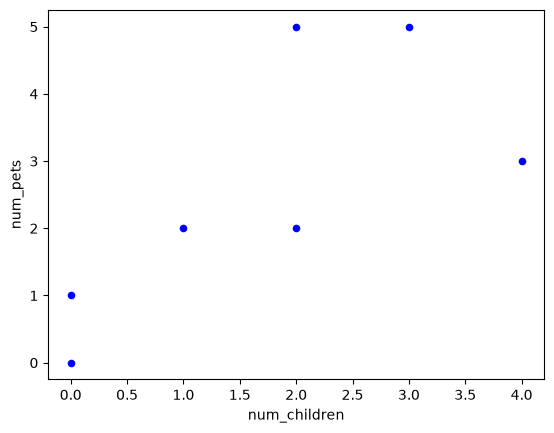

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

# a scatter plot comparing num_children and num_pets
df.plot(kind='scatter',x='num_children',y='num_pets',color='blue')
plt.show()

# Wir sehen:
# kind = "scatter" wählt die Form des plots
# x,y = "", auswahl der Werte/Achsen die geplottet werden sollen
# color= Farbe der Datenpunkte
# Typen an plots sind hier zu finden: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html#examples-using-matplotlib-pyplot-plot
# Alternative zu "kind = ''" --> statt .plot() direkten Plottype ansprechen, z.B.: .scatter()

<Axes: xlabel='name'>

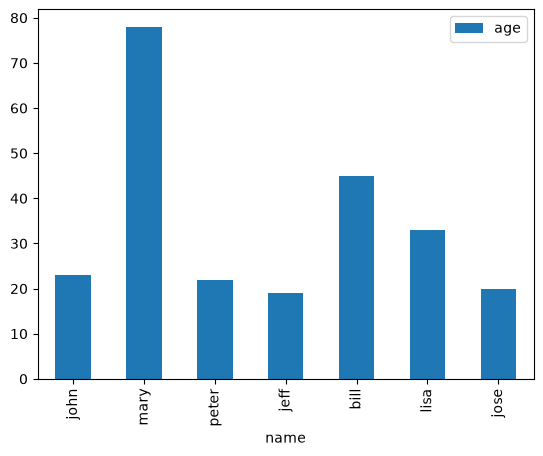

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

# a simple line plot
df.plot(kind='bar',x='name',y='age')

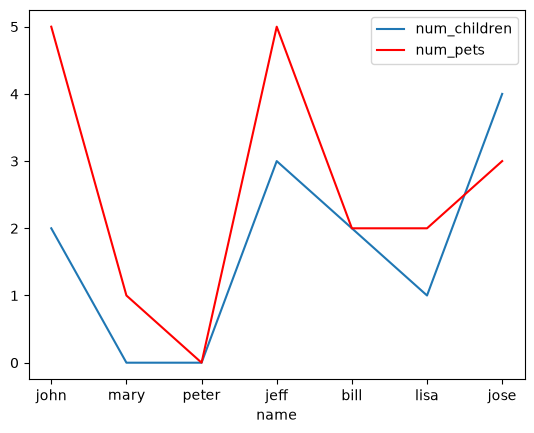

In [35]:
import matplotlib.pyplot as plt
import pandas as pd

# 'get current axis'
ax = plt.gca()

df.plot(kind='line',x='name',y='num_children', ax=ax)
df.plot(kind='line',x='name',y='num_pets', color='red', ax=ax)

plt.show()

### Persistieren eines Graphen

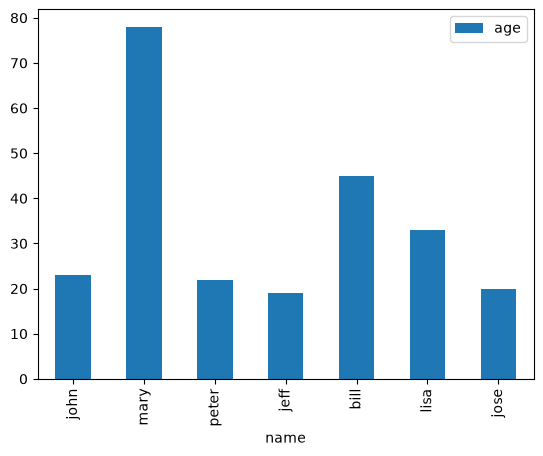

In [38]:
import matplotlib.pyplot as plt
import pandas as pd

df.plot(kind='bar',x='name',y='age')

plt_name = "abc"

# the plot gets saved to 'output.png'
plt.savefig(f'plot_graphs/{plt_name}.png')

### Verwendung von Aggregationsfunktionen

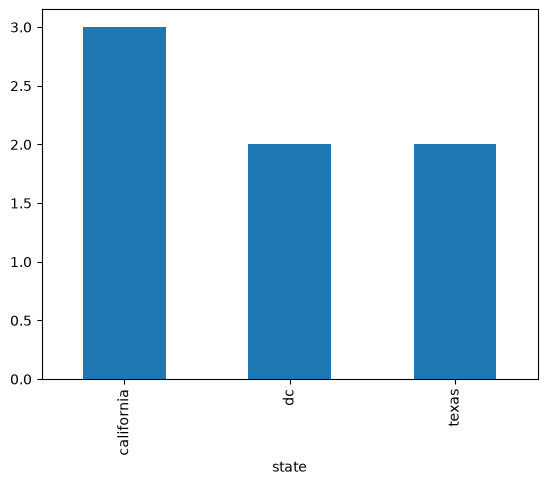

,name,age,gender,state,num_children,num_pets
0,john,23,M,california,2,5
1,mary,78,F,dc,0,1
2,peter,22,M,california,0,0
3,jeff,19,M,dc,3,5
4,bill,45,M,california,2,2
5,lisa,33,F,texas,1,2
6,jose,20,M,texas,4,3


In [41]:
import matplotlib.pyplot as plt
import pandas as pd

df.groupby('state')['name'].nunique().plot(kind='bar')
plt.show()

df

Verwendung von Aggregation mit einer dummyvariable und einer doppelten Aggegation

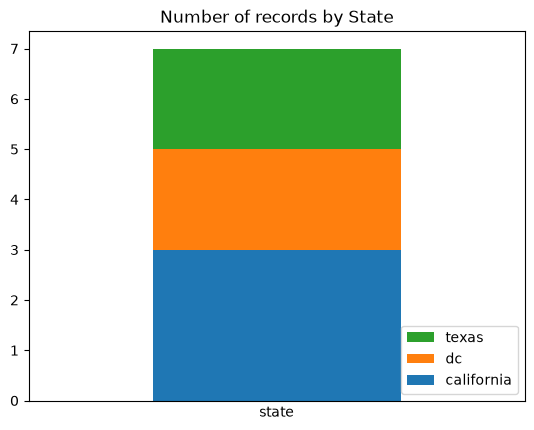

,name,age,gender,state,num_children,num_pets
0,john,23,M,california,2,5
1,mary,78,F,dc,0,1
2,peter,22,M,california,0,0
3,jeff,19,M,dc,3,5
4,bill,45,M,california,2,2
5,lisa,33,F,texas,1,2
6,jose,20,M,texas,4,3


In [43]:
import matplotlib.pyplot as plt

# create dummy variable them group by that
# set the legend to false because we'll fix it later
df.assign(dummy = 1).groupby(
  ['dummy','state']
).size().to_frame().unstack().plot(kind='bar',stacked=True,legend=False)

plt.title('Number of records by State')

# other it'll show up as 'dummy' 
plt.xlabel('state')

# disable ticks in the x axis
plt.xticks([]) 

# fix the legend
current_handles, _ = plt.gca().get_legend_handles_labels()
reversed_handles = reversed(current_handles)

labels = reversed(df['state'].unique())

plt.legend(reversed_handles,labels,loc='lower right')
plt.show()
df

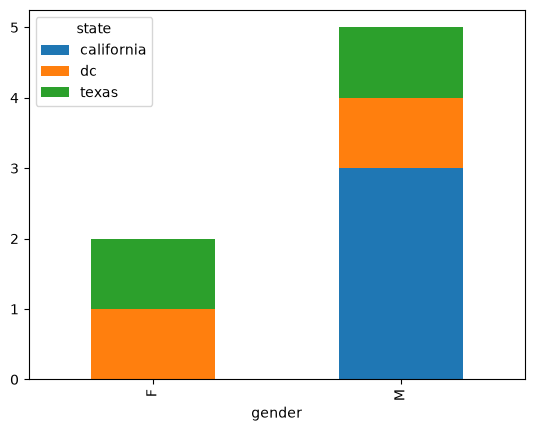

In [47]:
import matplotlib.pyplot as plt
import pandas as pd

df.groupby(['gender','state']).size().unstack().plot(kind='bar',stacked=True) # count by gender, split per state
plt.show()

### Beispiel mit numerischen Werten in einer Kategorie

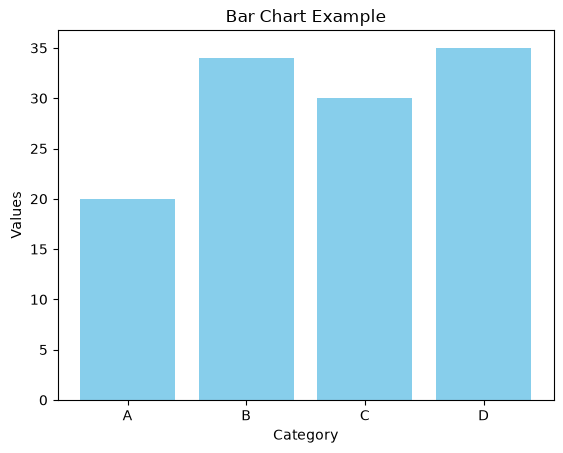

In [ ]:
import pandas
import matplotlib

data = {'Category': ['A', 'B', 'C', 'D'], 'Values': [20, 34, 30, 35]}
df = pd.DataFrame(data)

plt.bar(df['Category'], df['Values'], color='skyblue')
plt.xlabel("Category")
plt.ylabel("Values")
plt.title("Bar Chart Example")
plt.show()

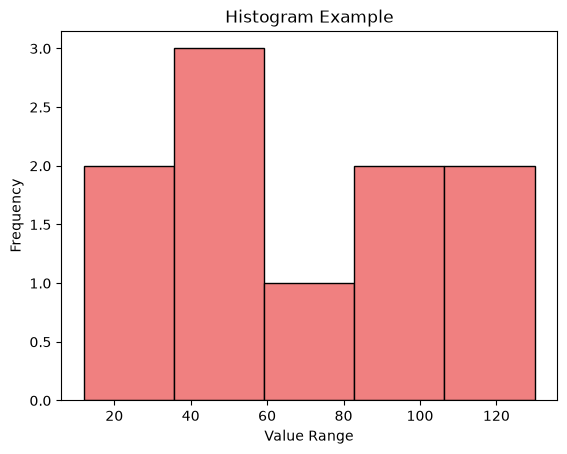

In [53]:
import pandas
import matplotlib

df = pd.DataFrame({'Values': [12, 23, 45, 36, 56, 78, 89, 95, 110, 130]})

plt.hist(df['Values'], bins=5, color='lightcoral', edgecolor='black')
plt.xlabel("Value Range")
plt.ylabel("Frequency")
plt.title("Histogram Example")
plt.show()

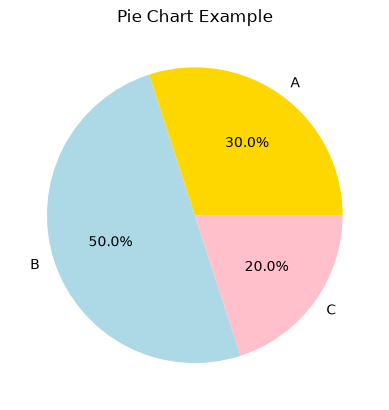

In [58]:
import pandas
import matplotlib

df = pd.DataFrame({'Category': ['A', 'B', 'C'], 'Values': [30, 50, 20]})

plt.pie(df['Values'], labels=df['Category'], autopct='%1.1f%%', colors=['gold', 'lightblue', 'pink'])
plt.title("Pie Chart Example")
plt.show()

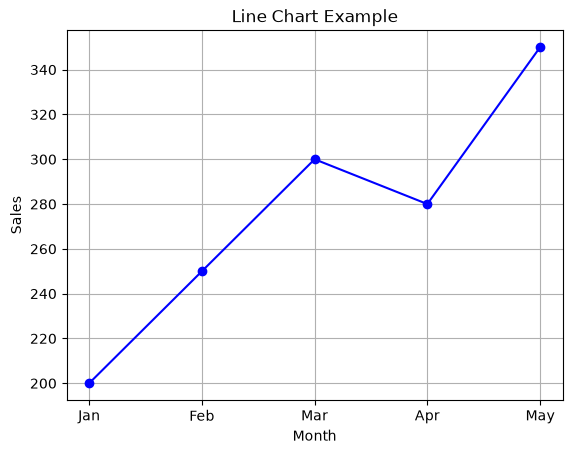

In [67]:
import pandas
import matplotlib

df = pd.DataFrame({'Month': ['Jan', 'Feb', 'Mar', 'Apr', 'May'], 'Sales': [200, 250, 300, 280, 350]})

plt.plot(df['Month'], df['Sales'], marker='o', linestyle='-', color='blue')
plt.xlabel("Month")
plt.ylabel("Sales")
plt.title("Line Chart Example")
plt.grid()
plt.show()

## Marker
Markierung von bestimmten oder allen Punkten
- https://www.w3schools.com/python/matplotlib_markers.asp

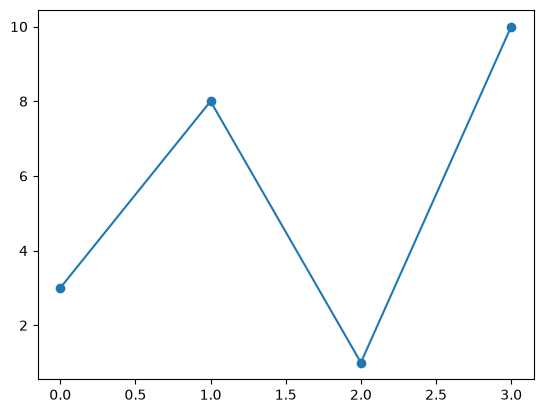

In [22]:
import matplotlib.pyplot as plt
import numpy as np

ypoints = np.array([3, 8, 1, 10])

plt.plot(ypoints, marker = 'o')
plt.show()

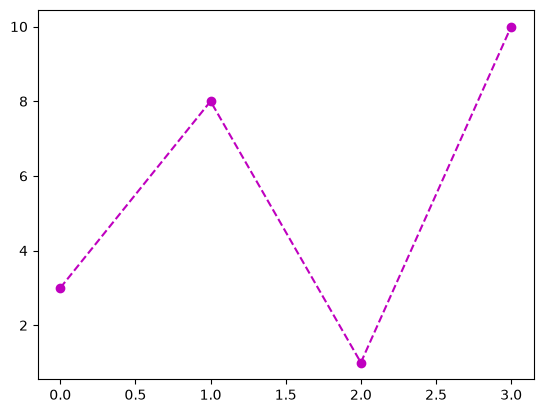

In [72]:
import matplotlib.pyplot as plt
import numpy as np

ypoints = np.array([3, 8, 1, 10])

plt.plot(ypoints, 'o--m')
plt.show()

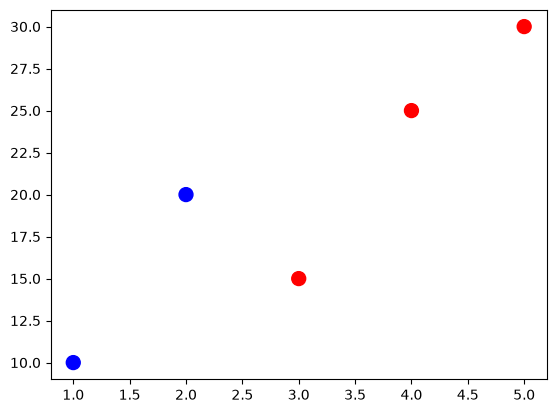

In [24]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([1, 2, 3, 4, 5])
y = np.array([10, 20, 15, 25, 30])
# Assign 'blue' to first 2 points, 'red' to the rest
colors = ['blue', 'blue', 'red', 'red', 'red']

plt.scatter(x, y, c=colors, s=100)
plt.show()   

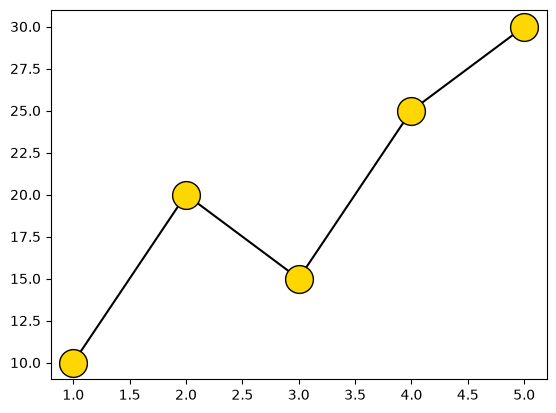

In [ ]:
plt.plot(x, y, color='black', linestyle='-', marker='o', 
         markersize=20, mfc='gold', mec='black')
plt.show()   

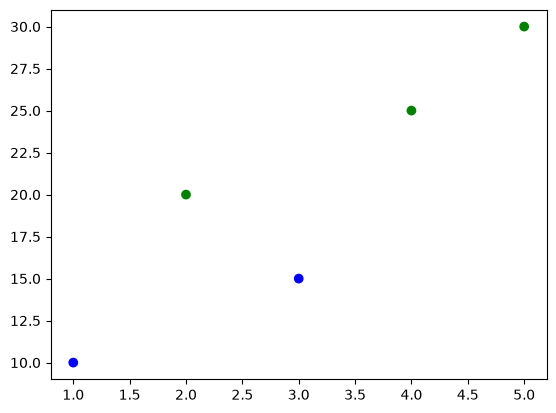

In [75]:
colors = ['green' if val > 15 else 'blue' for val in y]
plt.scatter(x, y, c=colors)
plt.show()   